# Graph object load

In [1]:
import cdlib
import networkx as nx

# Community discovery with cdlib

In [2]:
# Get graph
output_dir = "/Users/htang/Documents/PhD/Project - CAS/C3_Microbiome/2019-10-24_QIIME_CAS_COAST_meta_5/" + \
    "output/2020-09-25_fastspar_community/"
g = nx.readwrite.read_gml(path=output_dir + "net.graph.all.pos.txt", 
                         label="name")
g

In [3]:
# Get list of taxa
f = open(output_dir + "net.graph.all.pos.node.names.txt", "r")
taxa_list = f.read().splitlines()
taxa_list

['Moraxella.d253',
 'Streptococcus.4060',
 'Haemophilus.f579',
 'Corynebacterium.cb50',
 'Dolosigranulum.dd2e',
 'Haemophilus.bc0d',
 'Moraxella.b17f',
 'Streptococcus.3575',
 'Staphylococcus.29eb',
 'Neisseria.30f0',
 'Haemophilus.93a3',
 'Moraxellaceae.a5a0',
 'Veillonella.f2fe',
 'Veillonella.fb81',
 'Prevotella.ccff',
 'Neisseria.583c',
 'Corynebacterium.b1b8',
 'Moraxellaceae.6028',
 'Prevotella.6bee',
 'Prevotella.eedc',
 '[Prevotella].a061',
 'Streptococcus.b069',
 'Fusobacterium.9f11',
 'Leptotrichiaceae.540f',
 'Streptococcus.a3a3',
 'Gemellaceae.d800',
 'Leptotrichiaceae.f613',
 'Prevotella.9532',
 'Fusobacterium.a844',
 'Neisseria.3deb',
 'Lachnospiraceae.a69c',
 'Streptococcus.c79e',
 'Prevotella.5562',
 'Haemophilus.db79',
 'Lachnospiraceae.d32b',
 'Haemophilus.1648',
 'Veillonella.1dbd',
 'Prevotella.6f9b',
 'Granulicatella.86dc',
 'Pasteurellaceae.7682',
 'Porphyromonas.3e16',
 'Neisseriaceae.03f4',
 'Fusobacterium.22d5',
 'Actinobacillus.fb17',
 'Fusobacterium.b8a0',
 '

In [4]:
from cdlib import algorithms as cdlibalg
import random
import numpy as np
import matplotlib.pyplot as plt
import bct
from netneurotools import plotting
from netneurotools import cluster

In [5]:
# Set number of iterations
iter = 100

array([1, 2, 2, 1, 1, 2, 1, 3, 3, 2, 2, 1, 3, 3, 3, 3, 1, 1, 3, 3, 3, 3,
       3, 2, 3, 3, 2, 1, 3, 2, 2, 1, 3, 3, 3, 2, 2, 3, 3, 3, 3, 1, 3, 3,
       1, 3, 3, 3, 1, 3, 3, 3, 3, 4, 1, 3, 4, 3, 1, 3, 3, 3, 3, 3, 3, 2,
       3, 3, 4, 3, 4, 3, 3, 3, 3, 1, 2, 3, 1, 4, 3, 3, 3, 3, 4, 3, 3, 3,
       2, 3, 4, 3, 3, 4, 3, 4, 2, 2, 1, 4, 4, 2, 3, 4, 3, 3, 3, 3, 2, 2,
       3, 1, 3, 4, 3, 3, 4, 3, 1, 4, 1, 1, 3, 3, 1, 1, 3, 3, 4, 1, 3, 3,
       3, 2, 3, 2, 1, 3, 4, 3, 4, 1, 4, 4, 3, 1, 3, 3, 3, 4, 3, 1, 4, 3,
       1, 4, 3, 3, 1, 4, 3, 3, 4, 1, 3, 3, 3, 1, 1, 4, 3, 1, 1, 1, 1, 3,
       1, 1, 2, 3, 3, 4, 1, 1, 1, 1, 2, 3, 1, 3, 3, 1, 2, 1, 1, 1, 3, 1,
       1, 1, 4, 1, 1, 1, 4, 1, 3, 1, 3, 1, 1, 3, 1, 1, 3, 4, 1, 4, 3, 3,
       1, 1, 1, 3, 1, 3, 3, 1, 1, 1, 4, 1, 1, 1, 3, 1, 3, 1, 1, 1, 2, 3,
       1, 1, 4, 4, 1, 3, 1, 3, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 1, 3,
       1, 3, 1, 3, 1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 1, 3, 1, 4, 1, 1, 3, 3,
       3, 1, 1, 3, 1, 1, 1, 1, 4, 3, 1, 3, 4, 4, 1,

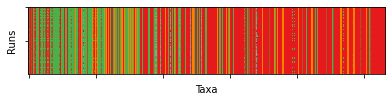

In [6]:
# Louvain
# Reference implementation: https://github.com/taynaud/python-louvain
# Can set resolution
# Can't set null model
# Can randomise start (true/false) but can't intrinsically set random seed (default false)
louvain_cdlib_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    louvain_cdlib_com = cdlibalg.louvain(g, resolution=1, randomize=True)
    louvain_cdlib_com.communities
    # louvain_cdlib_com.communities returns taxa names in list of n lists
    # where n is number of communities len(louvain_cdlib_com.communities)
    num_com = len(louvain_cdlib_com.communities)
    # for each taxa in each community
    membership = [None]*len(taxa_list)
    for com in range(num_com):
        for taxa in louvain_cdlib_com.communities[com]:
            # Get index from taxa_list
            index = taxa_list.index(taxa)
            # Make list where index equal to com number
            membership[index] = com
    louvain_cdlib_allcoms[x] = np.array(membership)
louvain_cdlib_cons = \
    cluster.find_consensus(np.column_stack(louvain_cdlib_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_cdlib_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_cdlib_cons

array([1, 2, 2, 1, 1, 2, 1, 3, 3, 2, 2, 1, 3, 3, 3, 3, 1, 1, 2, 3, 3, 3,
       3, 2, 3, 3, 2, 1, 2, 2, 2, 1, 3, 3, 2, 2, 2, 3, 3, 3, 3, 1, 3, 3,
       1, 3, 3, 3, 1, 3, 3, 3, 3, 4, 1, 3, 4, 3, 1, 3, 3, 3, 3, 3, 3, 2,
       3, 3, 4, 3, 4, 3, 3, 3, 2, 1, 2, 3, 1, 4, 3, 3, 1, 3, 4, 3, 3, 3,
       2, 3, 4, 3, 3, 4, 3, 4, 2, 2, 1, 4, 4, 2, 3, 4, 3, 3, 3, 3, 2, 2,
       3, 1, 3, 4, 3, 3, 4, 3, 1, 4, 1, 1, 3, 3, 1, 1, 3, 3, 4, 1, 3, 3,
       3, 2, 3, 2, 1, 3, 4, 3, 4, 1, 4, 4, 3, 1, 3, 3, 3, 4, 3, 1, 4, 3,
       1, 4, 3, 3, 1, 4, 3, 3, 4, 1, 3, 3, 3, 1, 1, 4, 3, 1, 1, 1, 1, 3,
       1, 1, 2, 3, 3, 4, 1, 1, 1, 1, 2, 3, 1, 3, 3, 1, 2, 1, 1, 1, 3, 1,
       1, 1, 4, 1, 1, 1, 4, 1, 3, 1, 3, 1, 1, 1, 1, 1, 3, 4, 1, 4, 3, 3,
       1, 1, 1, 3, 1, 4, 3, 1, 1, 1, 4, 1, 1, 1, 3, 1, 3, 1, 1, 1, 2, 3,
       1, 1, 4, 4, 1, 3, 1, 3, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 1, 3,
       1, 3, 1, 3, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 3, 1, 4, 1, 1, 3, 3,
       3, 1, 1, 3, 1, 1, 1, 1, 4, 3, 1, 3, 4, 4, 1,

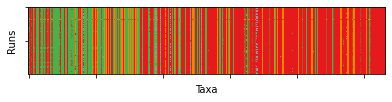

In [7]:
# Leiden
# Reference implementation: https://github.com/vtraag/leidenalg
# Can't set resolution
# Can't set null model 
# Can't set random seed, but can set initial membership (default = singleton partitions)
# need to manually set weights? (default = None)
leiden_cdlib_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    leiden_cdlib_com = cdlibalg.leiden(g, weights="weight")
    leiden_cdlib_com.communities
    # leiden_cdlib_com.communities returns taxa names in list of n lists
    # where n is number of communities len(leiden_cdlib_com.communities)
    num_com = len(leiden_cdlib_com.communities)
    # for each taxa in each community
    membership = [None]*len(taxa_list)
    for com in range(num_com):
        for taxa in leiden_cdlib_com.communities[com]:
            # Get index from taxa_list
            index = taxa_list.index(taxa)
            # Make list where index equal to com number
            membership[index] = com
    leiden_cdlib_allcoms[x] = np.array(membership)
leiden_cdlib_cons = \
    cluster.find_consensus(np.column_stack(leiden_cdlib_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_cdlib_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_cdlib_cons

# Community discovery with igraph (python)

In [33]:
import igraph as ig
import leidenalg as la
import cairo

g2 = ig.Graph.Read_GML(output_dir + "net.graph.all.pos.txt")
g2

array([1, 2, 2, 1, 1, 2, 1, 3, 3, 2, 2, 1, 3, 3, 3, 3, 1, 1, 2, 3, 3, 3,
       3, 2, 3, 3, 2, 1, 2, 2, 2, 1, 3, 3, 2, 2, 2, 3, 3, 3, 3, 1, 3, 3,
       2, 3, 3, 3, 1, 3, 3, 3, 3, 4, 1, 3, 4, 3, 1, 3, 3, 3, 3, 3, 3, 2,
       3, 3, 4, 3, 4, 3, 3, 3, 2, 1, 2, 3, 1, 4, 3, 3, 5, 3, 4, 3, 3, 3,
       2, 3, 4, 3, 3, 4, 3, 4, 2, 2, 1, 4, 4, 2, 3, 4, 3, 3, 3, 3, 2, 2,
       3, 1, 3, 4, 3, 3, 4, 3, 1, 4, 1, 1, 3, 3, 1, 1, 3, 3, 4, 1, 3, 3,
       3, 2, 3, 2, 1, 3, 4, 3, 4, 1, 4, 4, 3, 1, 3, 3, 3, 4, 3, 1, 4, 3,
       1, 4, 3, 3, 1, 4, 3, 3, 4, 1, 3, 3, 3, 1, 1, 4, 3, 1, 2, 1, 1, 3,
       1, 1, 2, 3, 3, 4, 1, 1, 1, 1, 2, 3, 1, 4, 3, 1, 2, 1, 1, 1, 5, 1,
       1, 1, 4, 1, 1, 1, 4, 1, 3, 1, 3, 1, 1, 5, 1, 1, 3, 4, 1, 4, 3, 3,
       1, 1, 1, 3, 1, 4, 3, 1, 1, 1, 4, 1, 1, 1, 3, 1, 3, 1, 1, 1, 2, 5,
       1, 1, 4, 4, 1, 3, 1, 3, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 1, 3,
       1, 3, 1, 3, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 3, 1, 4, 1, 1, 3, 3,
       3, 1, 1, 3, 1, 1, 1, 1, 4, 5, 1, 3, 4, 4, 1,

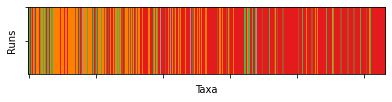

In [9]:
# Louvain (multilevel)
# Community structure based on the multilevel algorithm of Blondel et al.
# Can't set resolution
# Can't set null model
# Can't set random seed
# Can return communities at each level, or final community (default)
louvain_igraph_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    louvain_igraph_com = ig.Graph.community_multilevel(g2, weights="weight")
    louvain_igraph_allcoms[x] = np.array(louvain_igraph_com.membership)
louvain_igraph_cons = \
    cluster.find_consensus(np.column_stack(louvain_igraph_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_igraph_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_igraph_cons

array([1, 2, 2, 1, 1, 2, 1, 3, 3, 2, 2, 1, 3, 3, 3, 3, 1, 1, 2, 3, 3, 3,
       3, 2, 3, 3, 2, 1, 2, 2, 2, 1, 3, 3, 2, 2, 2, 3, 3, 3, 3, 1, 3, 3,
       1, 3, 3, 3, 1, 3, 3, 3, 3, 4, 1, 3, 4, 3, 1, 3, 3, 3, 3, 3, 3, 2,
       3, 3, 4, 3, 4, 3, 3, 3, 2, 1, 2, 3, 1, 4, 3, 3, 1, 3, 4, 3, 3, 3,
       2, 3, 4, 3, 3, 4, 3, 4, 2, 2, 1, 4, 4, 2, 3, 4, 3, 3, 3, 3, 2, 2,
       3, 1, 3, 4, 3, 3, 4, 3, 1, 4, 1, 1, 3, 3, 1, 1, 3, 3, 4, 1, 3, 3,
       3, 2, 3, 2, 1, 3, 4, 3, 4, 1, 4, 4, 3, 1, 3, 3, 3, 4, 3, 1, 4, 3,
       1, 4, 3, 3, 1, 4, 3, 3, 4, 1, 3, 3, 3, 1, 1, 4, 3, 1, 1, 1, 1, 3,
       1, 1, 2, 3, 3, 4, 1, 1, 1, 1, 2, 3, 1, 3, 3, 1, 2, 1, 1, 1, 3, 1,
       1, 1, 4, 1, 1, 1, 4, 1, 3, 1, 3, 1, 1, 1, 1, 1, 3, 4, 1, 4, 3, 3,
       1, 1, 1, 3, 1, 4, 3, 1, 1, 1, 4, 1, 1, 1, 3, 1, 3, 1, 1, 1, 2, 3,
       1, 1, 4, 4, 1, 3, 1, 3, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 1, 3,
       1, 3, 1, 3, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 3, 1, 4, 1, 1, 3, 3,
       3, 1, 1, 3, 1, 1, 1, 1, 4, 3, 1, 3, 4, 4, 1,

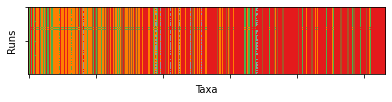

In [39]:
# Leiden
# Finds the community structure of the graph using the Leiden algorithm of Traag, van Eck & Waltman.
# Can set resolution
# Can set null model (but can only choose CPM vs. modularity = Newman-Girvan)
# Can't set random seed, but can set initial membership (default = singleton partitions)
# beta - parameter affecting the randomness in the Leiden algorithm. \
# This affects only the refinement step of the algorithm.

leiden_ig_mod_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    leiden_ig_mod_com = ig.Graph.community_leiden(g2, objective_function="modularity", \
                                              weights="weight", \
                                              resolution_parameter=1.0, \
                                              beta=0.01, \
                                              initial_membership=None, \
                                              n_iterations=2, \
                                              node_weights=None)
    leiden_ig_mod_allcoms[x] = np.array(leiden_ig_mod_com.membership)
leiden_ig_mod_cons = \
    cluster.find_consensus(np.column_stack(leiden_ig_mod_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_ig_mod_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_ig_mod_cons

array([ 1,  1,  2,  1,  1,  1,  3,  2,  2,  2,  1,  4,  2,  2,  2,  2,  1,
        1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  5,  2,  1,  2,  1,  2,  2,
        2,  2,  2,  2,  2,  2,  2,  5,  2,  2,  5,  2,  2,  2,  1,  2,  2,
        2,  2,  1,  1,  2,  1,  2,  1,  2,  2,  2,  2,  2,  2,  5,  2,  2,
        1,  2,  1,  2,  2,  2,  2,  3,  2,  2,  1,  1,  2,  2,  5,  2,  1,
        2,  2,  2,  2,  2,  1,  2,  2,  1,  2,  1,  2,  2,  6,  1,  1,  2,
        2,  1,  2,  2,  2,  2,  2,  2,  2,  1,  2,  1,  2,  2,  1,  2,  1,
        1,  1,  1,  2,  2,  1,  5,  2,  2,  1,  1,  2,  2,  2,  2,  2,  2,
        1,  2,  1,  2,  5,  1,  1,  1,  2,  1,  2,  2,  2,  1,  2,  1,  1,
        2,  1,  1,  2,  2,  1,  1,  2,  2,  1,  1,  2,  2,  2,  7,  1,  1,
        2,  5,  1,  7,  5,  2,  1,  1,  2,  2,  7,  1,  5,  1,  5,  1,  2,
        2,  1,  5,  2,  1,  2,  1,  5,  1,  2,  1,  1,  3,  1,  5,  5,  1,
        1,  1,  2,  1,  2,  1,  1,  5,  1,  1,  2,  1,  1,  1,  2,  2,  1,
        1,  1,  2,  1,  5

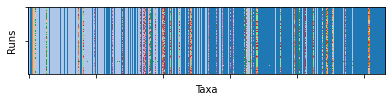

In [40]:
# CPM as objective function results in ~500 communities if resolution parameter = 1.0
# Lambda = 0.01 generates about 19 clusters of unequal size, dominated by 4-5
# Lambda = 0.005 generates about 14 clusters of unequal size, dominated by 4 
# Lambda = 0.0025 generates about 15 clusters of unequal size, dominated by 2 large ones
# Lambda = 0.001 generates 8 clusters of unequal size, dominated by 2 large ones 
# Use resolution parameter = 0.0025 for now as it seems to give 
# roughly equivalent number of clusters to other methods...

# Beta = parameter affecting the randomness in the Leiden algorithm. 
# This affects only the refinement step of the algorithm.
# Use default beta = 0.01 for now

leiden_ig_cpm_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    leiden_ig_cpm_com = ig.Graph.community_leiden(g2, objective_function="CPM", \
                                              weights="weight", \
                                              resolution_parameter=0.0025, \
                                              beta=0.01, \
                                              initial_membership=None, \
                                              n_iterations=2, \
                                              node_weights=None)
    leiden_ig_cpm_allcoms[x] = np.array(leiden_ig_cpm_com.membership)
leiden_ig_cpm_cons = \
    cluster.find_consensus(np.column_stack(leiden_ig_cpm_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_ig_cpm_allcoms, cmap='tab20', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_ig_cpm_cons

# Community discovery with python-louvain

array([1, 2, 2, 1, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       1, 2, 2, 2, 1, 2, 2, 2, 2, 3, 1, 2, 3, 2, 1, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 3, 2, 3, 2, 2, 2, 2, 1, 2, 2, 1, 3, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 3, 2, 2, 3, 2, 3, 2, 2, 1, 3, 3, 2, 2, 3, 2, 2, 2, 2, 2, 2,
       2, 1, 2, 3, 2, 2, 3, 2, 1, 3, 1, 1, 2, 2, 1, 1, 2, 2, 3, 1, 2, 2,
       2, 2, 2, 2, 1, 2, 3, 2, 3, 1, 3, 3, 2, 1, 2, 2, 2, 3, 2, 1, 3, 2,
       1, 3, 2, 2, 1, 3, 2, 2, 3, 1, 2, 2, 2, 1, 1, 3, 2, 1, 1, 1, 1, 2,
       1, 1, 2, 2, 2, 3, 1, 1, 1, 1, 2, 2, 1, 2, 2, 1, 2, 1, 1, 1, 2, 1,
       1, 1, 3, 1, 1, 1, 3, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 3, 1, 3, 2, 2,
       1, 1, 1, 2, 1, 2, 2, 1, 1, 1, 3, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2, 2,
       1, 1, 3, 3, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 3, 1, 1, 2, 2,
       2, 1, 1, 2, 1, 1, 1, 1, 3, 2, 1, 2, 3, 3, 1,

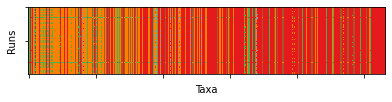

In [22]:
# JSON representation of results
import community as community_louvain

# Louvain
# Can set resolution
# Can't set null model
# Can set random seed

louvain_pl_allcoms = [None]*iter
for x in range(iter):
    # x = 1
    random.seed(x)
    louvain_pl_com = community_louvain.best_partition(g, partition=None, \
                                                  weight='weight', \
                                                  resolution=1.0, \
                                                  # random_state=x, \
                                                  randomize=True)
    # np.array(list(louvain_pl_com.values()))
    louvain_pl_allcoms[x] = np.array(list(louvain_pl_com.values()))
louvain_pl_cons = \
    cluster.find_consensus(np.column_stack(louvain_pl_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_pl_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_pl_cons                       

# Community discovery with louvain from Traag

In [42]:
# Louvain (RBC)
# Can set resolution
# Can set null model
# Can't set random seed but can set initial membership (default = singleton partitions)

import louvain as lou

<ipython-input-42-c8fbff793007>:6: DeprecationWarning: This package has been superseded by the `leidenalg` package and will no longer be maintained. Please upgrade to the `leidenalg` package.
  import louvain as lou


array([1, 2, 2, 1, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       1, 2, 2, 2, 1, 2, 2, 2, 2, 3, 1, 2, 3, 2, 1, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 3, 2, 3, 2, 2, 2, 2, 1, 2, 2, 1, 3, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 3, 2, 2, 3, 2, 3, 2, 2, 1, 3, 3, 2, 2, 3, 2, 2, 2, 2, 2, 2,
       2, 1, 2, 3, 2, 2, 3, 2, 1, 3, 1, 1, 2, 2, 1, 1, 2, 2, 3, 1, 2, 2,
       2, 2, 2, 2, 1, 2, 3, 2, 3, 1, 3, 3, 2, 1, 2, 2, 2, 3, 2, 1, 3, 2,
       1, 3, 2, 2, 1, 3, 2, 2, 3, 1, 2, 2, 2, 1, 1, 3, 2, 1, 1, 1, 1, 2,
       1, 1, 2, 2, 2, 3, 1, 1, 1, 1, 2, 2, 1, 2, 2, 1, 2, 1, 1, 1, 2, 1,
       1, 1, 3, 1, 1, 1, 3, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 3, 1, 3, 2, 2,
       1, 1, 1, 2, 1, 2, 2, 1, 1, 1, 3, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2, 2,
       1, 1, 3, 3, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 3, 1, 1, 2, 2,
       2, 1, 1, 2, 1, 1, 1, 1, 3, 2, 1, 2, 3, 3, 1,

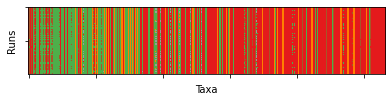

In [44]:
# Can set resolution
# Can set null model
# Can set seed
louvain_lou_rbc_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    louvain_lou_rbc_com = lou.find_partition(g2, \
                                      partition_type = lou.RBConfigurationVertexPartition, \
                                       initial_membership=None, \
                                       weights="weight", \
                                      seed=x,
                                       resolution_parameter = 1.0)
    louvain_lou_rbc_allcoms[x] = np.array(louvain_lou_rbc_com.membership)
louvain_lou_rbc_cons = \
    cluster.find_consensus(np.column_stack(louvain_lou_rbc_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_rbc_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_rbc_cons

array([ 1,  1,  2,  1,  1,  1,  3,  2,  2,  2,  1,  1,  2,  2,  2,  2,  1,
        1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,  2,  1,  2,  1,  2,  2,
        2,  2,  2,  2,  2,  2,  2,  4,  2,  2,  2,  2,  2,  2,  1,  2,  2,
        2,  2,  1,  1,  2,  1,  2,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        1,  2,  1,  2,  2,  2,  2,  3,  2,  2,  1,  1,  2,  2,  4,  2,  1,
        2,  2,  2,  2,  2,  1,  2,  2,  1,  2,  1,  2,  2,  5,  1,  1,  2,
        2,  1,  2,  2,  2,  2,  2,  2,  2,  1,  2,  1,  2,  2,  1,  2,  1,
        1,  1,  1,  2,  2,  1,  6,  2,  2,  1,  1,  2,  2,  2,  2,  2,  2,
        1,  2,  1,  2,  1,  1,  1,  1,  2,  1,  2,  2,  2,  1,  2,  1,  1,
        2,  1,  1,  2,  2,  1,  1,  2,  2,  1,  1,  2,  2,  2,  7,  1,  1,
        2,  6,  1,  7,  8,  2,  1,  1,  2,  2,  9,  1,  1,  1,  1,  1,  2,
        2,  1,  6,  2,  1,  2,  1,  6,  1,  2,  1,  1,  3,  1,  6,  9,  1,
        1,  1,  2,  1,  2,  1,  1,  4,  1,  1,  2,  1,  1,  1,  2,  2,  1,
        1,  1,  2,  1,  1

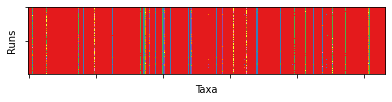

In [45]:
# Can set resolution
# Can set null model
# Can set seed
louvain_lou_cpm_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    louvain_lou_cpm_com = lou.find_partition(g2, \
                                      partition_type = lou.CPMVertexPartition, \
                                       initial_membership=None, \
                                       weights="weight", \
                                      seed=x,
                                       resolution_parameter = 0.0025)
    louvain_lou_cpm_allcoms[x] = np.array(louvain_lou_cpm_com.membership)
louvain_lou_cpm_cons = \
    cluster.find_consensus(np.column_stack(louvain_lou_cpm_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_lou_cpm_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_lou_cpm_cons

# Community discovery with leidenalg

In [23]:
# Leiden (Modularity)
# Can't set resolution
# Can set null model
# Can't set random seed but can set initial membership (default = singleton partitions)
# optimiser = la.Optimiser()
# leiden_la_mvp_com = la.ModularityVertexPartition(g2, initial_membership=None, \
#                                              weights="weight")
# optimiser.optimise_partition(leiden_la_mvp_com)
# len(set(leiden_la_mvp_com.membership))

array([1, 2, 2, 1, 1, 2, 1, 3, 3, 2, 2, 1, 3, 3, 3, 3, 1, 1, 2, 3, 3, 3,
       3, 2, 3, 3, 2, 1, 2, 2, 2, 1, 3, 3, 2, 2, 2, 3, 3, 3, 3, 1, 3, 3,
       1, 3, 3, 3, 1, 3, 3, 3, 3, 4, 1, 3, 4, 3, 1, 3, 3, 3, 3, 3, 3, 2,
       3, 3, 4, 3, 4, 3, 3, 3, 2, 1, 2, 3, 1, 4, 3, 3, 1, 3, 4, 3, 3, 3,
       2, 3, 4, 3, 3, 4, 3, 4, 2, 2, 1, 4, 4, 2, 3, 4, 3, 3, 3, 3, 2, 2,
       3, 1, 3, 4, 3, 3, 4, 3, 1, 4, 1, 1, 3, 3, 1, 1, 3, 3, 4, 1, 3, 3,
       3, 2, 3, 2, 1, 3, 4, 3, 4, 1, 4, 4, 3, 1, 3, 3, 3, 4, 3, 1, 4, 3,
       1, 4, 3, 3, 1, 4, 3, 3, 4, 1, 3, 3, 3, 1, 1, 4, 3, 1, 1, 1, 1, 3,
       1, 1, 2, 3, 3, 4, 1, 1, 1, 1, 2, 3, 1, 3, 3, 1, 2, 1, 1, 1, 3, 1,
       1, 1, 4, 1, 1, 1, 4, 1, 3, 1, 3, 1, 1, 1, 1, 1, 3, 4, 1, 4, 3, 3,
       1, 1, 1, 3, 1, 4, 3, 1, 1, 1, 4, 1, 1, 1, 3, 1, 3, 1, 1, 1, 2, 3,
       1, 1, 4, 4, 1, 3, 1, 3, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 1, 3,
       1, 3, 1, 3, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 3, 1, 4, 1, 1, 3, 3,
       3, 1, 1, 3, 1, 1, 1, 1, 4, 3, 1, 3, 4, 4, 1,

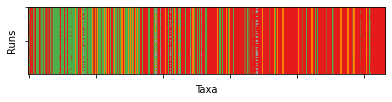

In [24]:
# Can't set resolution
# Can set null model
# Can set seed
leiden_la_mvp_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    leiden_la_mvp_com = la.find_partition(g2, \
                                          partition_type = la.ModularityVertexPartition, \
                                          initial_membership=None, \
                                          weights="weight", \
                                          n_iterations=-1, 
                                          max_comm_size=0, 
                                          seed=x)
    leiden_la_mvp_allcoms[x] = np.array(leiden_la_mvp_com.membership)
leiden_la_mvp_cons = \
    cluster.find_consensus(np.column_stack(leiden_la_mvp_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_mvp_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_mvp_cons

In [25]:
# Leiden (RBC) - resolution parameter = 1 should be identical to modularity
# Can set resolution
# Can set null model
# Can't set random seed but can set initial membership (default = singleton partitions)
# optimiser = la.Optimiser()
# leiden_la_rbc_com = la.RBConfigurationVertexPartition(g2, initial_membership=None, \
#                                                       weights="weight", \
#                                                       node_sizes=[1]*532, \
#                                                       resolution_parameter=1.0)
# optimiser.optimise_partition(leiden_la_rbc_com)
# len(set(leiden_la_rbc_com.membership))

array([1, 2, 2, 1, 1, 2, 1, 3, 3, 2, 2, 1, 3, 3, 3, 3, 1, 1, 2, 3, 3, 3,
       3, 2, 3, 3, 2, 1, 2, 2, 2, 1, 3, 3, 2, 2, 2, 3, 3, 3, 3, 1, 3, 3,
       1, 3, 3, 3, 1, 3, 3, 3, 3, 4, 1, 3, 4, 3, 1, 3, 3, 3, 3, 3, 3, 2,
       3, 3, 4, 3, 4, 3, 3, 3, 2, 1, 2, 3, 1, 4, 3, 3, 1, 3, 4, 3, 3, 3,
       2, 3, 4, 3, 3, 4, 3, 4, 2, 2, 1, 4, 4, 2, 3, 4, 3, 3, 3, 3, 2, 2,
       3, 1, 3, 4, 3, 3, 4, 3, 1, 4, 1, 1, 3, 3, 1, 1, 3, 3, 4, 1, 3, 3,
       3, 2, 3, 2, 1, 3, 4, 3, 4, 1, 4, 4, 3, 1, 3, 3, 3, 4, 3, 1, 4, 3,
       1, 4, 3, 3, 1, 4, 3, 3, 4, 1, 3, 3, 3, 1, 1, 4, 3, 1, 1, 1, 1, 3,
       1, 1, 2, 3, 3, 4, 1, 1, 1, 1, 2, 3, 1, 3, 3, 1, 2, 1, 1, 1, 3, 1,
       1, 1, 4, 1, 1, 1, 4, 1, 3, 1, 3, 1, 1, 1, 1, 1, 3, 4, 1, 4, 3, 3,
       1, 1, 1, 3, 1, 4, 3, 1, 1, 1, 4, 1, 1, 1, 3, 1, 3, 1, 1, 1, 2, 3,
       1, 1, 4, 4, 1, 3, 1, 3, 1, 3, 1, 1, 3, 1, 1, 3, 1, 1, 1, 1, 1, 3,
       1, 3, 1, 3, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 3, 1, 4, 1, 1, 3, 3,
       3, 1, 1, 3, 1, 1, 1, 1, 4, 3, 1, 3, 4, 4, 1,

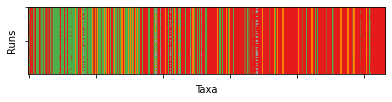

In [34]:
# Can set resolution
# Can set null model
# Can set seed
leiden_la_rbc_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    leiden_la_rbc_com = la.find_partition(g2, \
                                      partition_type = la.RBConfigurationVertexPartition, \
                                       initial_membership=None, \
                                       weights="weight", \
                                       n_iterations=-1, 
                                       max_comm_size=0, 
                                      seed=x,
                                       resolution_parameter = 1.0)
    leiden_la_rbc_allcoms[x] = np.array(leiden_la_rbc_com.membership)
leiden_la_rbc_cons = \
    cluster.find_consensus(np.column_stack(leiden_la_rbc_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_rbc_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_rbc_cons

In [ ]:
# Leiden (CPM)
# Can set resolution
# Can set null model
# Can't set random seed but can set initial membership (default = singleton partitions)
# optimiser = la.Optimiser()
# leiden_la_cpm_com = la.CPMVertexPartition(g2, initial_membership=None, \
#                                           weights="weight", \
#                                           resolution_parameter=1.0)
# optimiser.optimise_partition(leiden_la_cpm_com)
# len(set(leiden_la_cpm_com.membership))

array([ 1,  1,  2,  1,  1,  1,  3,  2,  2,  2,  1,  4,  2,  2,  2,  2,  1,
        1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  5,  2,  1,  2,  1,  2,  2,
        2,  2,  2,  2,  2,  2,  2,  6,  2,  2,  7,  2,  2,  2,  1,  2,  2,
        2,  2,  1,  1,  2,  1,  2,  1,  2,  2,  2,  2,  2,  2,  5,  2,  2,
        1,  2,  1,  2,  2,  2,  2,  3,  2,  2,  1,  1,  2,  2,  6,  2,  1,
        2,  2,  2,  2,  2,  1,  2,  2,  1,  2,  1,  2,  2,  8,  1,  1,  2,
        2,  1,  2,  2,  2,  2,  2,  2,  2,  1,  2,  1,  2,  2,  1,  2,  1,
        1,  1,  1,  2,  2,  1,  9,  2,  2,  1,  1,  2,  2,  2,  2,  2,  2,
        1,  2,  1,  2, 10,  1,  1,  1,  2,  1,  2,  2,  2,  1,  2,  1,  1,
        2,  1,  1,  2,  2,  1,  1,  2,  2,  1,  1,  2,  2,  2, 11,  1,  1,
        2,  9,  1, 11, 10,  2,  1,  1,  2,  2, 11,  1,  5,  1,  7,  1,  2,
        2,  1,  6,  2,  1,  2,  1,  9,  1,  2,  1,  1,  3,  1,  9,  7,  1,
        1,  1,  2,  1,  2,  1,  1,  6,  1,  1,  2,  1,  1,  1,  2,  2,  1,
        1,  1,  2,  1,  6

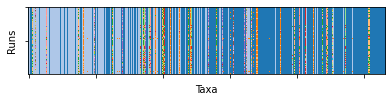

In [37]:
# Can set resolution
# Can set null model
# Can set seed
leiden_la_cpm_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    leiden_la_cpm_com =  la.find_partition(g2, \
                                      partition_type = la.CPMVertexPartition, \
                                       initial_membership=None, \
                                       weights="weight", \
                                       n_iterations=-1, \
                                       max_comm_size=0, \
                                      seed=x, resolution_parameter = 0.0025)
    leiden_la_cpm_allcoms[x] = np.array(leiden_la_cpm_com.membership)
leiden_la_cpm_cons = \
    cluster.find_consensus(np.column_stack(leiden_la_cpm_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(leiden_la_cpm_allcoms, cmap='tab20', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
leiden_la_cpm_cons

# Community discovery with bctpy

array([1, 2, 2, 1, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       1, 2, 2, 2, 1, 2, 2, 2, 2, 3, 1, 2, 3, 2, 1, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 3, 2, 3, 2, 2, 2, 2, 1, 2, 2, 1, 3, 2, 2, 2, 2, 3, 2, 2, 2,
       2, 2, 3, 2, 2, 3, 2, 3, 2, 2, 1, 3, 3, 2, 2, 3, 2, 2, 2, 2, 2, 2,
       2, 1, 2, 3, 2, 2, 3, 2, 1, 3, 1, 1, 2, 2, 1, 1, 2, 2, 3, 1, 2, 2,
       2, 2, 2, 2, 1, 2, 3, 2, 3, 1, 3, 3, 2, 1, 2, 2, 2, 3, 2, 1, 3, 2,
       1, 3, 2, 2, 1, 3, 2, 2, 3, 1, 2, 2, 2, 1, 1, 3, 2, 1, 1, 1, 1, 2,
       1, 1, 2, 2, 2, 3, 1, 1, 1, 1, 2, 2, 1, 2, 2, 1, 2, 1, 1, 1, 2, 1,
       1, 1, 3, 1, 1, 1, 3, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 3, 1, 3, 2, 2,
       1, 1, 1, 2, 1, 2, 2, 1, 1, 1, 3, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2, 2,
       1, 1, 3, 3, 1, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 3, 1, 1, 2, 2,
       2, 1, 1, 2, 1, 1, 1, 1, 3, 2, 1, 2, 3, 3, 1,

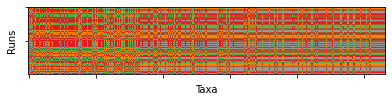

In [36]:
corr = np.genfromtxt(output_dir + 'net.graph.all.pos.adj.txt', \
                                   delimiter=" ", dtype=None, encoding=None)

# Can set resolution (= gamma)
# Can set null model (modularity, Potts = CPM, negative symmetric, negative asymmetric)
# Can't set seed but can set initial membership
louvain_bctpy_allcoms = [None]*iter
for x in range(iter):
    # x = 0
    random.seed(x)
    louvain_bctpy_com, louvain_bctpy_Q = bct.community_louvain(corr, gamma=1)
    louvain_bctpy_allcoms[x] = np.array(louvain_bctpy_com)
louvain_bctpy_cons = \
    cluster.find_consensus(np.column_stack(louvain_bctpy_allcoms), \
                       seed=1)

# Create plot of membership by runs ~ taxa
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(louvain_bctpy_allcoms, cmap='Set1', interpolation='none')
ax.set(ylabel='Runs', xlabel='Taxa', \
       xticklabels=[], yticklabels=[])
louvain_bctpy_cons

# Output all to file for R

In [46]:
import csv

method_range =  ("louvain_cdlib", "leiden_cdlib", "louvain_igraph",
                "leiden_ig_mod", "leiden_ig_cpm", "louvain_pl",
                 "louvain_lou_rbc", "louvain_lou_cpm",
                "leiden_la_mvp", "leiden_la_rbc", "leiden_la_cpm",
                "louvain_bctpy")

for x in method_range:
    with open(output_dir + str(x) + "_allcoms.csv", "w") as f:
        csvwriter = csv.writer(f)
        csvwriter.writerows(globals()[str(x) + "_allcoms"])
    np.savetxt(output_dir + str(x) + "_cons.csv", \
           (globals()[str(x) + "_cons"]-1).astype(int), fmt="%i", delimiter=",")